# 28. Stellantis N.V. — 이탈의 부호: 어느 방향이 실제 불량과 관련되는가 (작업 6)
- D4 규칙은 날짜 안 |강건 z|(크기)만 본다. 여기서는 z를 부호로 나눠 낮은 쪽(z⁻)과 높은 쪽(z⁺)의 불량 관련성을 따로 본다.
- Stellantis N.V. 값은 0~1 정규화 파형의 요약이라 단위가 없다. **방향만 본다.** 가압력이 전부 0인 284타점은 가압력·I/F 분석에서 뺀다.
- 위치 교란(특정 위치에 불량이 몰림)을 피하려고 두 기준을 낸다. (a) D4와 같은 날짜 안 z, (b) 같은 위치(전 기간) 중앙값 대비 z + 같은 위치 안 AUROC.
- 모델을 학습하지 않는다. 사양·추천은 바꾸지 않는다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy import stats
import br
from br import spec as S, plot as P, stat as T
from wl import data as wldata
from wl.metrics import within_loc_auroc
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
X, day, cnt, y, _ = S.load_polito("raw")
P0 = wldata.load_polito(); loc, body = P0["loc"].values, P0["body"].values
VARS = [("cur", "전류"), ("time", "통전시간"), ("force", "가압력"), ("heat", "입열량 V·I·t"), ("i_over_f", "전류/가압력"), ("dynres", "동저항 V/I")]
print("타점", len(y), "불량", int(y.sum()), "| 가압력 결측", int(X.force.isna().sum()))

def robust_z(v, grp):
    s = pd.Series(v); g = pd.Series(grp)
    med = s.groupby(g).transform("median"); mad = (s - med).abs().groupby(g).transform("median") * 1.4826
    return ((s - med) / mad.replace(0, np.nan)).clip(-10, 10).values

타점 1976 불량 79 | 가압력 결측 284


In [2]:
rng = np.random.default_rng(26); ub = np.unique(body)
BOOT = [np.concatenate([np.flatnonzero(body == b_) for b_ in rng.choice(ub, len(ub))]) for _ in range(300)]
rows = []
for base, grp in (("(a) 날짜 안", day), ("(b) 같은 위치 기준", loc)):
    for c, cname in VARS:
        z = robust_z(X[c].values, grp); ok = ~np.isnan(z)
        zz, yy, ll = z[ok], y[ok], loc[ok]
        zm, zp = np.clip(-zz, 0, None), np.clip(zz, 0, None)
        b, se = T.firth(np.column_stack([np.ones(ok.sum()), zm, zp]), yy)
        r = {"기준": base, "변수": cname, "n": int(ok.sum()), "불량": int(yy.sum())}
        for nm, m in (("z≤−1(뚜렷이 낮음)", zz <= -1), ("|z|<1", np.abs(zz) < 1), ("z≥+1(뚜렷이 높음)", zz >= 1)):
            r[nm] = f"{int(yy[m].sum())}/{int(m.sum())} ({yy[m].mean()*100 if m.sum() else np.nan:.1f}%)"
        r["낮은 쪽 OR/SD [95%]"] = f"{np.exp(b[1]):.2f} [{np.exp(b[1]-T.Z*se[1]):.2f}, {np.exp(b[1]+T.Z*se[1]):.2f}]"
        r["높은 쪽 OR/SD [95%]"] = f"{np.exp(b[2]):.2f} [{np.exp(b[2]-T.Z*se[2]):.2f}, {np.exp(b[2]+T.Z*se[2]):.2f}]"
        r["_bm"], r["_bp"], r["_sm"], r["_sp"] = b[1], b[2], se[1], se[2]
        wa = within_loc_auroc(yy, zz, ll)
        idx_ok = np.flatnonzero(ok); pos = {v: i for i, v in enumerate(idx_ok)}
        bs = []
        for bi in BOOT[:200]:
            bi = [pos[i] for i in bi if i in pos]
            bs.append(within_loc_auroc(yy[bi], zz[bi], ll[bi]))
        r["같은 위치 안 AUROC(높을수록 위험이면 >0.5) [95%]"] = f"{wa:.3f} [{np.nanquantile(bs,.025):.3f}, {np.nanquantile(bs,.975):.3f}]"
        r["_wa"] = wa
        rows.append(r)
SG = pd.DataFrame(rows)
def verdict(r):
    lo_sig = r._bm - T.Z * r._sm > 0; hi_sig = r._bp - T.Z * r._sp > 0
    if lo_sig and not hi_sig: return "낮은 쪽이 위험"
    if hi_sig and not lo_sig: return "높은 쪽이 위험"
    if lo_sig and hi_sig: return "양쪽 모두"
    return "뚜렷한 방향 없음"
SG["판정(Firth 95% 구간 기준)"] = SG.apply(verdict, axis=1)
display(SG.drop(columns=["_bm", "_bp", "_sm", "_sp", "_wa"]))
SG.drop(columns=["_bm", "_bp", "_sm", "_sp", "_wa"]).to_csv(br.RES / "polito_sign_direction.csv", index=False, encoding="utf-8-sig")

,기준,변수,n,불량,z≤−1(뚜렷이 낮음),|z|<1,z≥+1(뚜렷이 높음),낮은 쪽 OR/SD [95%],높은 쪽 OR/SD [95%],같은 위치 안 AUROC(높을수록 위험이면 >0.5) [95%],판정(Firth 95% 구간 기준)
0,(a) 날짜 안,전류,1973,79,3/144 (2.1%),27/1257 (2.1%),49/572 (8.6%),"0.75 [0.36, 1.58]","1.65 [1.34, 2.03]","0.520 [0.375, 0.629]",높은 쪽이 위험
1,(a) 날짜 안,통전시간,1950,73,0/157 (0.0%),27/1241 (2.2%),46/552 (8.3%),"0.71 [0.26, 1.95]","2.23 [1.66, 2.98]","0.472 [0.349, 0.564]",높은 쪽이 위험
2,(a) 날짜 안,가압력,1692,71,1/65 (1.5%),50/1092 (4.6%),20/535 (3.7%),"0.08 [0.02, 0.24]","0.83 [0.74, 0.93]","0.528 [0.451, 0.598]",뚜렷한 방향 없음
3,(a) 날짜 안,입열량 V·I·t,1973,79,1/124 (0.8%),28/1221 (2.3%),50/628 (8.0%),"0.71 [0.27, 1.85]","1.90 [1.52, 2.38]","0.422 [0.298, 0.532]",높은 쪽이 위험
4,(a) 날짜 안,전류/가압력,1692,71,1/135 (0.7%),27/1101 (2.5%),43/456 (9.4%),"0.67 [0.27, 1.68]","2.12 [1.52, 2.95]","0.533 [0.379, 0.657]",높은 쪽이 위험
5,(a) 날짜 안,동저항 V/I,1973,79,10/253 (4.0%),54/1383 (3.9%),15/337 (4.5%),"1.31 [0.83, 2.08]","1.20 [0.90, 1.60]","0.496 [0.376, 0.604]",뚜렷한 방향 없음
6,(b) 같은 위치 기준,전류,1972,79,12/243 (4.9%),56/1347 (4.2%),11/382 (2.9%),"1.04 [0.82, 1.31]","1.03 [0.90, 1.19]","0.475 [0.363, 0.558]",뚜렷한 방향 없음
7,(b) 같은 위치 기준,통전시간,18,0,0/0 (nan%),0/16 (0.0%),0/2 (0.0%),"0.79 [0.00, 583.55]","1.13 [0.67, 1.89]","nan [nan, nan]",뚜렷한 방향 없음
8,(b) 같은 위치 기준,가압력,1692,71,9/262 (3.4%),44/1136 (3.9%),18/294 (6.1%),"0.84 [0.64, 1.10]","0.96 [0.85, 1.07]","0.584 [0.487, 0.706]",뚜렷한 방향 없음
9,(b) 같은 위치 기준,입열량 V·I·t,1972,79,16/264 (6.1%),48/1330 (3.6%),15/378 (4.0%),"1.27 [1.12, 1.44]","1.00 [0.84, 1.19]","0.393 [0.273, 0.492]",낮은 쪽이 위험


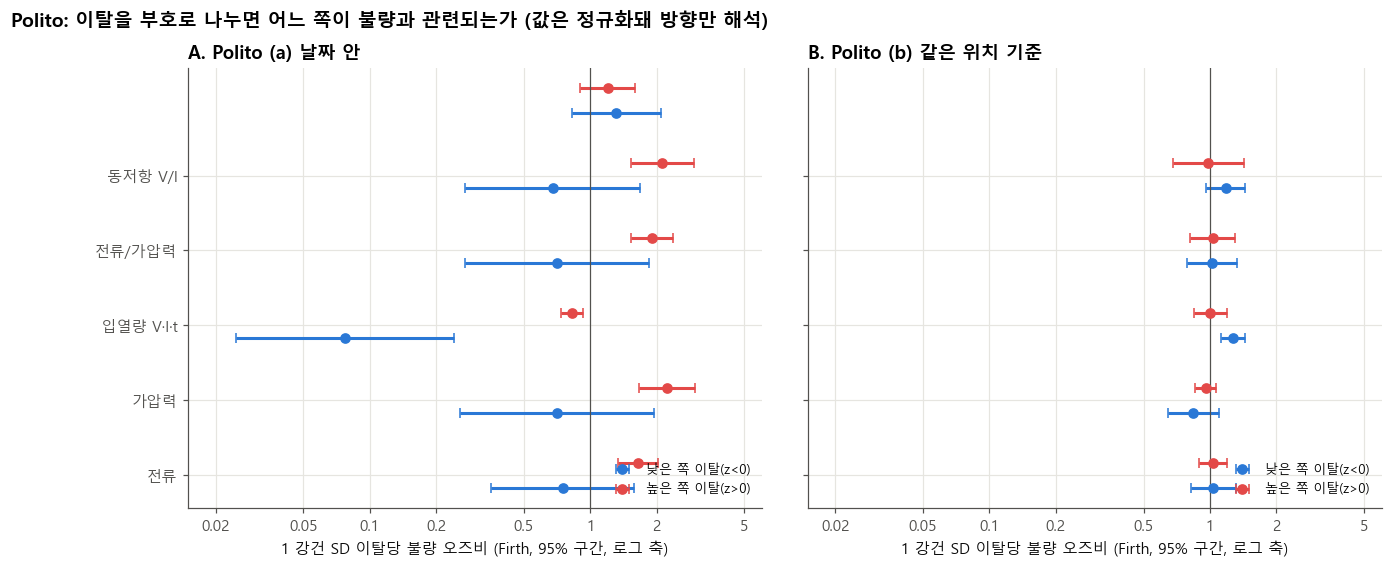

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True, gridspec_kw=dict(wspace=.08))
for ax, base in zip(axs, ("(a) 날짜 안", "(b) 같은 위치 기준")):
    d_ = SG[(SG.기준 == base) & (SG.n >= 100)].reset_index(drop=True); yy_ = np.arange(len(d_))
    for off, bcol, scol, col, lab in ((-.17, "_bm", "_sm", P.PAL[0], "낮은 쪽 이탈(z<0)"), (.17, "_bp", "_sp", P.PAL[7], "높은 쪽 이탈(z>0)")):
        e = np.exp(d_[bcol]); lo = np.exp(d_[bcol] - T.Z * d_[scol]); hi = np.exp(d_[bcol] + T.Z * d_[scol])
        ax.errorbar(e, yy_ + off, xerr=[e - lo, hi - e], fmt="o", color=col, capsize=3, label=lab)
    ax.axvline(1, color=P.INK2, lw=.8); ax.set_xscale("log")
    tk = [0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5]; ax.set_xticks(tk); ax.set_xticklabels([f"{t:g}" for t in tk]); ax.minorticks_off()
    ax.set_xlim(0.015, 6)
    ax.set_yticks(yy_); ax.set_yticklabels(d_.변수); ax.invert_yaxis()
    ax.set_xlabel("1 강건 SD 이탈당 불량 오즈비 (Firth, 95% 구간, 로그 축)")
    ax.set_title(f"{'A' if base.startswith('(a)') else 'B'}. Stellantis N.V. {base}", loc="left", fontweight="bold"); ax.legend(fontsize=8.5, loc="lower right")
fig.suptitle("Stellantis N.V.: 이탈을 부호로 나누면 어느 쪽이 불량과 관련되는가 (값은 정규화돼 방향만 해석)", x=.01, ha="left", fontsize=12.5, fontweight="bold")
P.save(fig, "24_polito_sign"); plt.show()